In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/leash-BELKA/sample_submission.csv
/kaggle/input/leash-BELKA/train.parquet
/kaggle/input/leash-BELKA/test.parquet
/kaggle/input/leash-BELKA/train.csv
/kaggle/input/leash-BELKA/test.csv


RDKit: Open-source cheminformatics. https://www.rdkit.org

In [2]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.1/33.1 MB 43.1 MB/s eta 0:00:00


In [3]:
!pip install duckdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 48.8 MB/s eta 0:00:00


DuckDB is an in-process SQL OLAP database management system designed to handle large amounts of data efficiently. It can be very useful in preprocessing large datasets for machine learning tasks, including balancing unbalanced data to reduce bias. Here’s how DuckDB can be utilized to address these tasks:
Handling Large Datasets
1.Efficient Query Execution:
DuckDB is optimized for running analytical queries on large datasets. It can quickly scan through and process large amounts of data stored in files like CSV or Parquet without the need to load everything into memory.
2.Columnar Storage:
DuckDB uses columnar storage, which is more efficient for analytical queries that process large volumes of data. This allows it to handle larger datasets more efficiently compared to row-based storage systems.

In [4]:
import duckdb
import pandas as pd

train_path = '/kaggle/input/leash-BELKA/train.parquet'
test_path = '/kaggle/input/leash-BELKA/test.parquet'

con = duckdb.connect()

df = con.query(f"""(SELECT *
                        FROM parquet_scan('{train_path}')
                        WHERE binds = 0
                        ORDER BY random()
                        LIMIT 30000)
                        UNION ALL
                        (SELECT *
                        FROM parquet_scan('{train_path}')
                        WHERE binds = 1
                        ORDER BY random()
                        LIMIT 30000)""").df()

con.close()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [5]:
df.head()

,id,buildingblock1_smiles,buildingblock2_smiles,buildingblock3_smiles,molecule_smiles,protein_name,binds
0,39811333,COc1cccc(NC(=O)OCC2c3ccccc3-c3ccccc32)c1C(=O)O,Cl.NCCC1CN(c2ncnc3[nH]ncc23)c2ccccc21,Nc1ccc2nsnc2c1,COc1cccc(Nc2nc(NCCC3CN(c4ncnc5[nH]ncc45)c4cccc...,HSA,0
1,235987253,O=C(O)C1c2ccccc2CN1C(=O)OCC1c2ccccc2-c2ccccc21,Cl.NCc1cocn1,Nc1ccnc(-c2ccccc2)c1,O=C(N[Dy])C1c2ccccc2CN1c1nc(NCc2cocn2)nc(Nc2cc...,sEH,0
2,202958896,O=C(Nc1ccc(I)cc1C(=O)O)OCC1c2ccccc2-c2ccccc21,CS(=O)C1(CN)CCC1,N#Cc1c[nH]nc1N,CS(=O)C1(CNc2nc(Nc3ccc(I)cc3C(=O)N[Dy])nc(Nc3n...,HSA,0
3,240031984,O=C(O)CNC(=O)OCC1c2ccccc2-c2ccccc21,Cc1cc(CN)ccc1Oc1ccc(Cl)cc1Cl.Cl,NCc1sncc1Br,Cc1cc(CNc2nc(NCC(=O)N[Dy])nc(NCc3sncc3Br)n2)cc...,HSA,0
4,225503468,O=C(Nc1nc(Cl)ccc1C(=O)O)OCC1c2ccccc2-c2ccccc21,Nc1ncccc1F,CC1(C)CC(CCN)C(=O)N1.Cl,CC1(C)CC(CCNc2nc(Nc3ncccc3F)nc(Nc3nc(Cl)ccc3C(...,sEH,0


In [6]:
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import OneHotEncoder

# Convert SMILES to RDKit molecules
df['molecule'] = df['molecule_smiles'].apply(Chem.MolFromSmiles)

# Generate ECFPs using rdFingerprintGenerator
def generate_ecfp(molecule, radius=2, bits=1024):
    if molecule is None:
        return None
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=bits)
    return list(generator.GetFingerprint(molecule))

df['ecfp'] = df['molecule'].apply(generate_ecfp)

In [7]:
# One-hot encode the protein_name
onehot_encoder = OneHotEncoder(sparse_output=False)
protein_onehot = onehot_encoder.fit_transform(df['protein_name'].values.reshape(-1, 1))

# Combine ECFPs and one-hot encoded protein_name
X = [ecfp + protein for ecfp, protein in zip(df['ecfp'].tolist(), protein_onehot.tolist())]
y = df['binds'].tolist()

# Split the data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Create and train the random forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]  # Probability of the positive class

# Calculate the mean average precision
map_score = average_precision_score(y_test, y_pred_proba)
print(f"Mean Average Precision (mAP): {map_score:.2f}")

Mean Average Precision (mAP): 0.96


In [8]:
import os
print(os.getcwd())

/kaggle/working


In [9]:
import os

# Process the test.parquet file chunk by chunk
test_file = '/kaggle/input/leash-BELKA/test.csv'
output_file = '/kaggle/working/submission.csv'# Specify the path and filename for the output file

# Read the test.parquet file into a pandas DataFrame
for df_test in pd.read_csv(test_file, chunksize=100000):

    # Generate ECFPs for the molecule_smiles
    df_test['molecule'] = df_test['molecule_smiles'].apply(Chem.MolFromSmiles)
    df_test['ecfp'] = df_test['molecule'].apply(generate_ecfp)

    # One-hot encode the protein_name
    protein_onehot = onehot_encoder.transform(df_test['protein_name'].values.reshape(-1, 1))

    # Combine ECFPs and one-hot encoded protein_name
    X_test = [ecfp + protein for ecfp, protein in zip(df_test['ecfp'].tolist(), protein_onehot.tolist())]

    # Predict the probabilities
    probabilities = rf_model.predict_proba(X_test)[:, 1]

    # Create a DataFrame with 'id' and 'probability' columns
    output_df = pd.DataFrame({'id': df_test['id'], 'binds': probabilities})

    # Save the output DataFrame to a CSV file
    output_df.to_csv(output_file, index=False, mode='a', header=not os.path.exists(output_file))

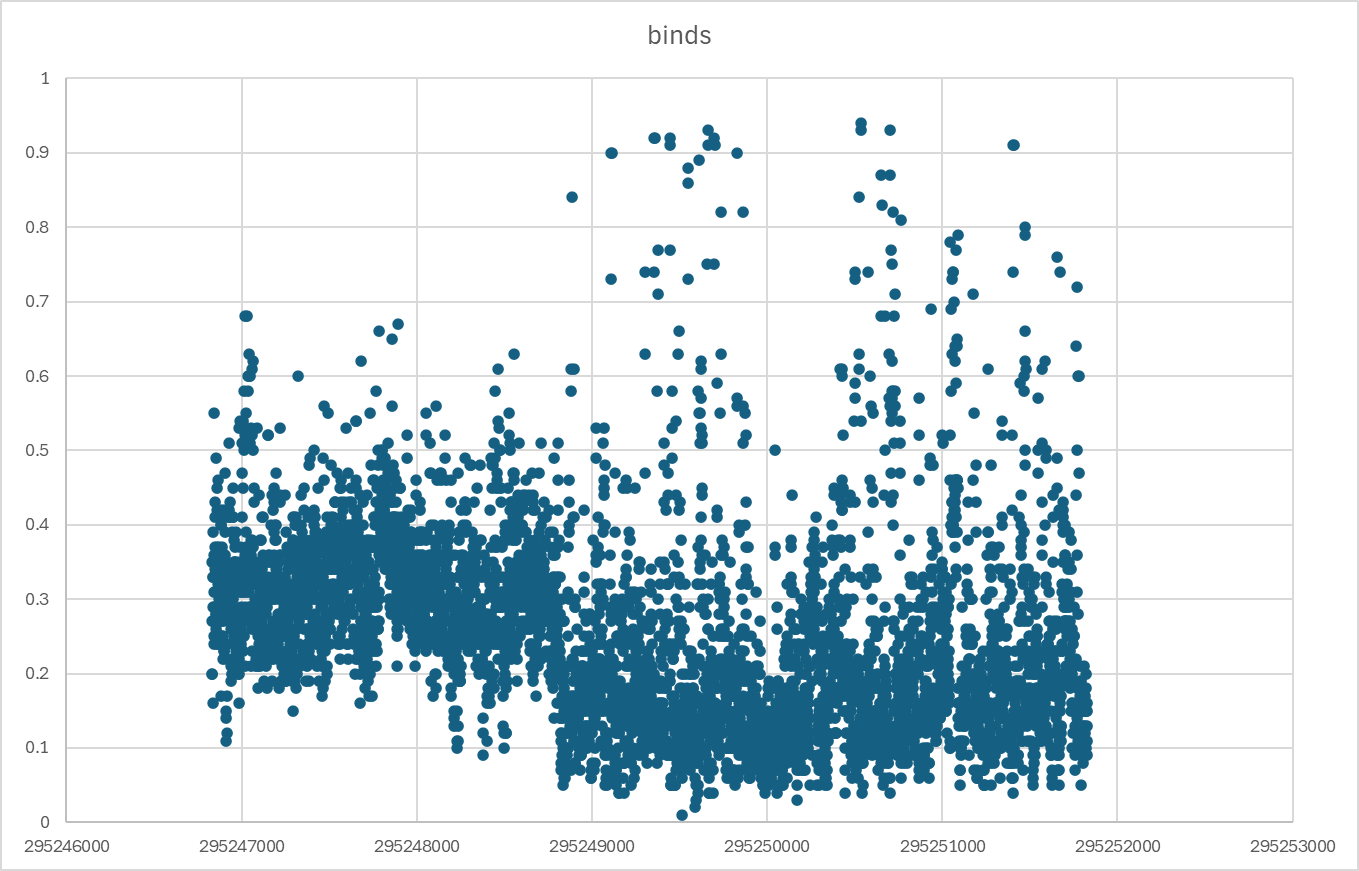!
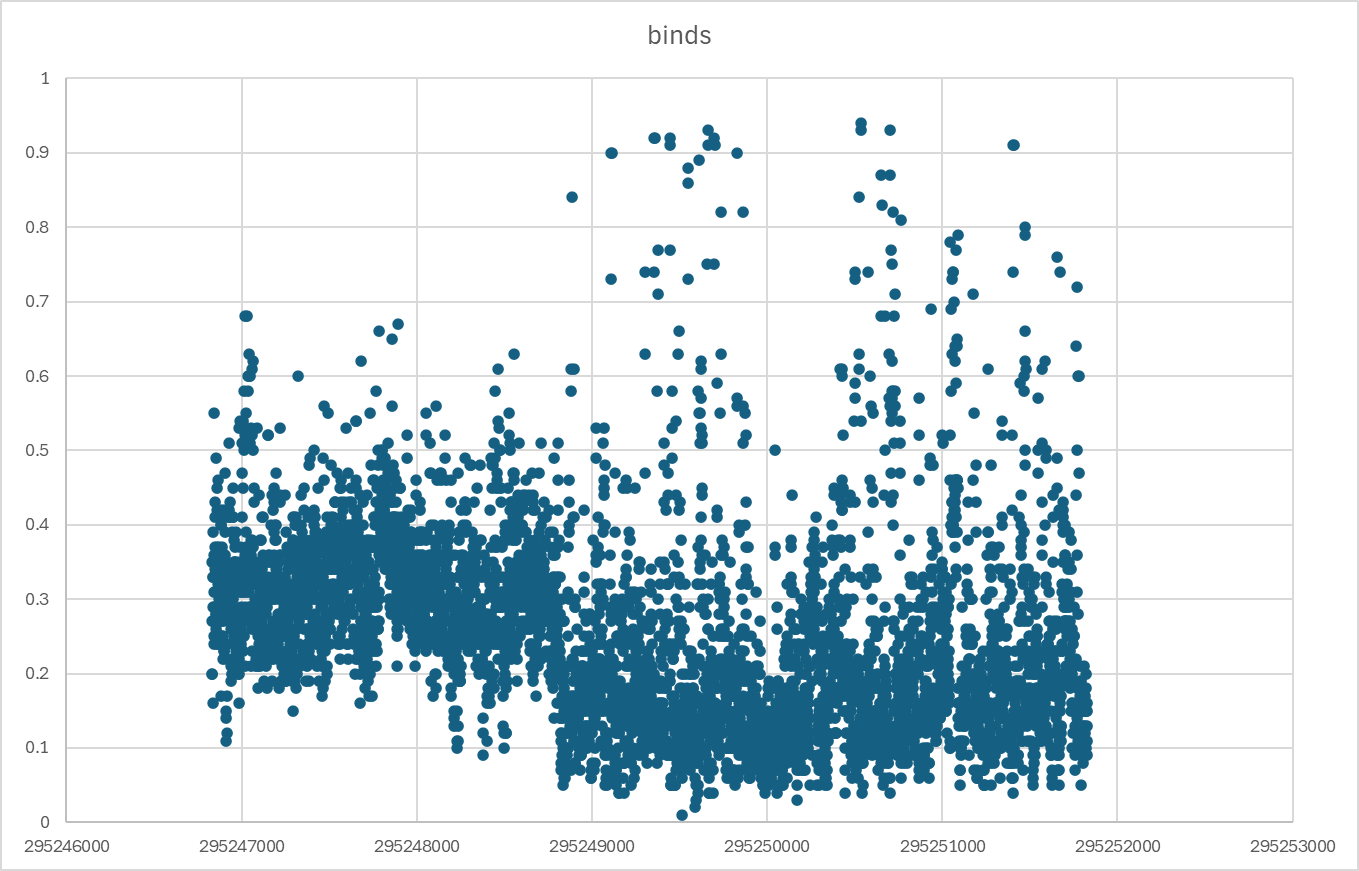